In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

titanic = pd.read_csv("../data/titanic_propre.csv")
titanic.shape

(889, 11)

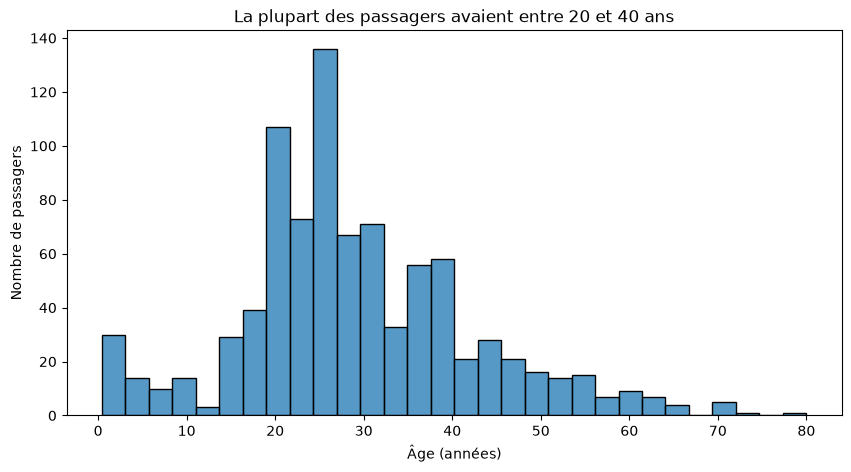

In [2]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(data=titanic, x="age", bins=30, ax=ax)
ax.set_title("La plupart des passagers avaient entre 20 et 40 ans")
ax.set_xlabel("Âge (années)")
ax.set_ylabel("Nombre de passagers")
fig.savefig("../figures/ages.png", dpi=150, bbox_inches="tight")
plt.show()

jai utilisé un histogramme car je montre la répartition d’une seule variable numérique (l’âge).
la plupart des passagers avaient entre 20 et 40 ans, et il y avait peu de personnes âgées. Le pic autour de 25 ans est du au fait qu'à l’exercice 8, j’ai rempli les 177 âges manquants avec la médiane de chaque groupe (par exemple 25 ans pour les hommes de 3e classe), ce qui a gonflé certaines barres.

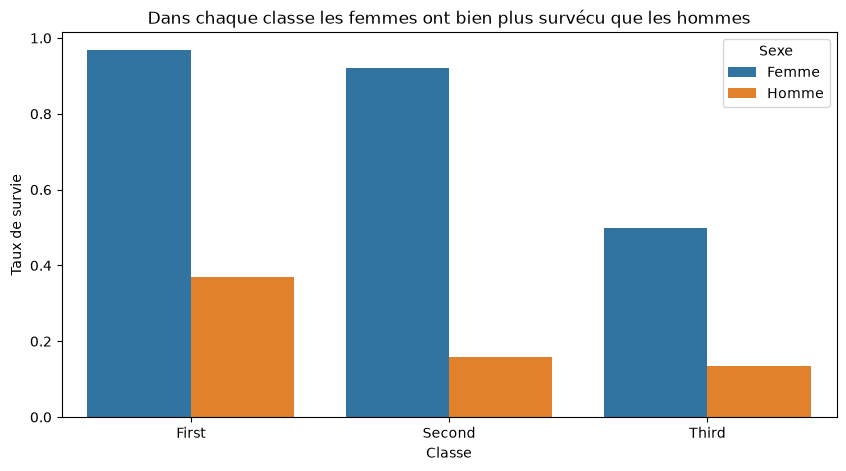

In [3]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(data=titanic, x="class", y="survived", hue="sex", hue_order=["female", "male"], order=["First", "Second", "Third"], errorbar=None, ax=ax)
ax.set_title("Dans chaque classe les femmes ont bien plus survécu que les hommes")
ax.set_xlabel("Classe")
ax.set_ylabel("Taux de survie")
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles, ["Femme", "Homme"], title="Sexe")
fig.savefig("../figures/survie_classe_sexe.png", dpi=150, bbox_inches="tight")
plt.show()

jai choisi le diagramme en barres car je compare un taux (une mesure) entre plusieurs catégories (la classe), avec la couleur pour le sexe.Dans les trois classes les femmes ont beaucoup mieux survécu que les hommes. En 1ere et 2e classe plus de 90 % des femmes ont survécu contre seulement 50 % en 3e classe. Les hommes ont peu survécu partout surtout en 2e et 3e classe

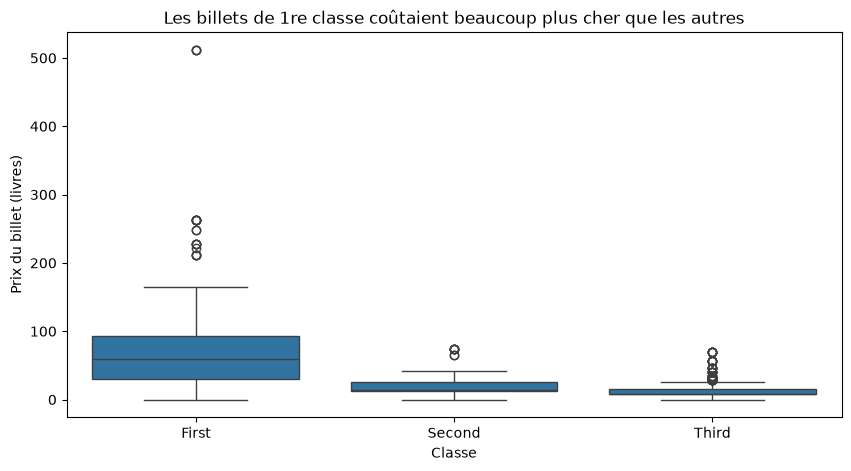

In [4]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data=titanic, x="class", y="fare", order=["First", "Second", "Third"], ax=ax)
ax.set_title("Les billets de 1re classe coûtaient beaucoup plus cher que les autres")
ax.set_xlabel("Classe")
ax.set_ylabel("Prix du billet (livres)")
fig.savefig("../figures/prix_classe.png", dpi=150, bbox_inches="tight")
plt.show()

boîte à moustaches car je compare la répartition d’une mesure (le prix) entre plusieurs catégories (la classe), et elle montre aussi les valeurs extrêmes.
les billets de 1ere classe coûtaient beaucoup plus cher que ceux de 2e et 3e classe . Les prix de 1ere classe variaient aussi énormément, avec quelques billets exceptionnels jusqu’à 512 . Les points isolés en 3e classe correspondent sûrement à des familles qui partageaient un même billet

In [5]:
taxis = sns.load_dataset("taxis")
taxis["pickup"] = pd.to_datetime(taxis["pickup"])

ca_par_jour = taxis.set_index("pickup").resample("D")["total"].sum()
ca_par_jour = ca_par_jour["2019-03-01":]
ca_par_jour.head()

pickup
2019-03-01    4213.83
2019-03-02    3319.02
2019-03-03    3027.32
2019-03-04    3269.08
2019-03-05    4377.38
Freq: D, Name: total, dtype: float64

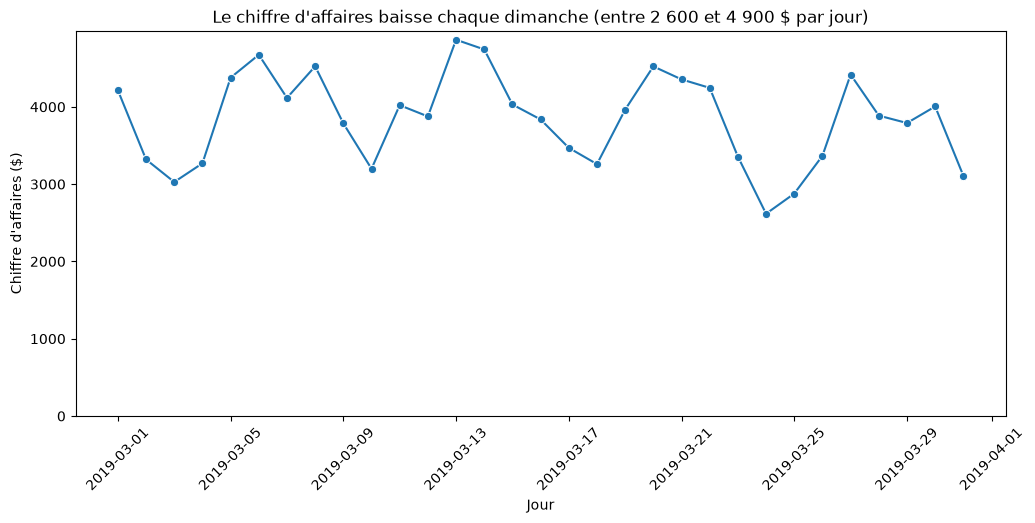

In [6]:
fig, ax = plt.subplots(figsize=(12, 5))
sns.lineplot(x=ca_par_jour.index, y=ca_par_jour.values, marker="o", ax=ax)
ax.set_title("Le chiffre d'affaires baisse chaque dimanche (entre 2 600 et 4 900 $ par jour)")
ax.set_xlabel("Jour")
ax.set_ylabel("Chiffre d'affaires ($)")
ax.set_ylim(bottom=0)
ax.tick_params(axis="x", rotation=45)
fig.savefig("../figures/ca_par_jour.png", dpi=150, bbox_inches="tight")
plt.show()

courbe car je montre comment une mesure (le chiffre d’affaires) évolue dans le temps.
en mars 2019 le chiffre d’affaires des taxis varie entre environ 2 600 et 4 900 $ par jour. On voit un rythme qui se répète chaque semaine  il baisse nettement tous les dimanches (3, 10, 17, 24 et 31 mars). L’activité des taxis suit donc le rythme du travail . J’ai retiré le 28 février, qui n’avait qu’une seule course.

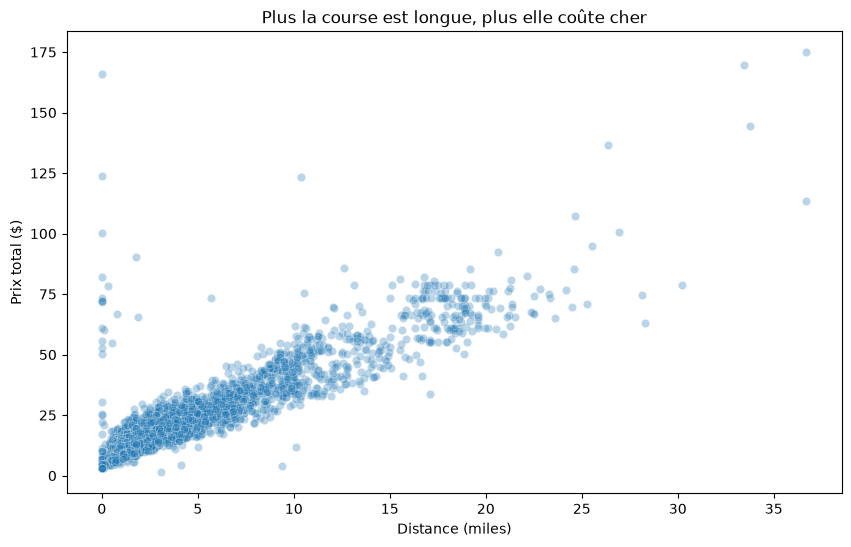

In [7]:
fig, ax = plt.subplots(figsize=(10, 6))
sns.scatterplot(data=taxis, x="distance", y="total", alpha=0.3, ax=ax)
ax.set_title("Plus la course est longue, plus elle coûte cher")
ax.set_xlabel("Distance (miles)")
ax.set_ylabel("Prix total ($)")
fig.savefig("../figures/distance_prix.png", dpi=150, bbox_inches="tight")
plt.show()

nuage de points car je cherche le lien entre deux mesures (la distance et le prix).
plus la course est longue, plus elle coûte cher : les points forment presque une ligne qui monte. La plupart des courses sont courtes et coûtent moins de 25 $. On voit aussi des points anormaux à distance 0 avec des prix élevés jusqu’à 166 $  ce sont les erreurs repérées à l’exercice 11.